Random Forest Model for Hardness Prediction

Dataset Information
Samples  : 500
Target   : Hv
Features : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']

Train-Test Split
Training samples : 400
Testing samples  : 100

Hyperparameter Optimization
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best Hyperparameters:
n_estimators        : 800
min_samples_split   : 2
min_samples_leaf    : 2
max_features        : 1.0
max_depth           : 10
bootstrap           : True

Best CV RMSE: 62.987 Hv

Model Performance

Training Set
R2   : 0.9823
RMSE : 29.906 Hv
MAE  : 21.713 Hv

Testing Set
R2   : 0.8660
RMSE : 74.637 Hv
MAE  : 49.434 Hv


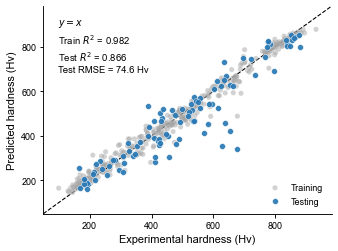


Completed

Generated Files:
1. RF_Parity_Plot.png
2. RF_Train_Test_Predictions.xlsx
3. RF_Hyperparameter_Search.csv
4. RF_Hardness_Model.joblib


In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    KFold,
)
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)


# ============================================================
# 1. Settings
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_ITER = 40
CV_FOLDS = 5

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
DATA_FILE = BASE_DIR / "Data.xlsx"

# Outputs
MODEL_FILE = BASE_DIR / "RF_Hardness_Model.joblib"
PREDICTION_FILE = BASE_DIR / "RF_Train_Test_Predictions.xlsx"
SEARCH_FILE = BASE_DIR / "RF_Hyperparameter_Search.csv"
FIGURE_FILE = BASE_DIR / "RF_Parity_Plot.png"


# ============================================================
# 2. Load data
# ============================================================

data = pd.read_excel(DATA_FILE)

# First column = target
target_name = data.columns[0]

# Remaining columns = input features
feature_names = list(data.columns[1:])


# Remove rows containing missing values
if data.isnull().values.any():

    print("Warning: Missing values detected.")
    print(data.isnull().sum())

    data = data.dropna().reset_index(drop=True)


X = data[feature_names]
y = data[target_name]


print("=" * 60)
print("Dataset Information")
print("=" * 60)

print(f"Samples  : {len(data)}")
print(f"Target   : {target_name}")
print(f"Features : {feature_names}")


# ============================================================
# 3. Train-test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)


print("\n" + "=" * 60)
print("Train-Test Split")
print("=" * 60)

print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")


# ============================================================
# 4. Random Forest and hyperparameter optimization
# ============================================================

rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


param_distributions = {

    "n_estimators": [
        200,
        300,
        400,
        500,
        600,
        700,
        800,
        900,
        1000,
        1200,
    ],

    "max_depth": [
        None,
        5,
        10,
        15,
        20,
        30,
        40,
    ],

    "min_samples_split": [
        2,
        4,
        6,
        8,
        10,
    ],

    "min_samples_leaf": [
        1,
        2,
        3,
        4,
        5,
    ],

    "max_features": [
        "sqrt",
        "log2",
        0.5,
        0.7,
        1.0,
    ],

    "bootstrap": [
        True,
        False,
    ],
}


cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)


random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True,
)


print("\n" + "=" * 60)
print("Hyperparameter Optimization")
print("=" * 60)


random_search.fit(
    X_train,
    y_train,
)


best_model = random_search.best_estimator_

best_cv_rmse = np.sqrt(
    -random_search.best_score_
)


print("\nBest Hyperparameters:")

for parameter, value in random_search.best_params_.items():
    print(f"{parameter:20s}: {value}")


print(
    f"\nBest CV RMSE: "
    f"{best_cv_rmse:.3f} Hv"
)


# ============================================================
# 5. Model evaluation
# ============================================================

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)


def calculate_metrics(y_true, y_pred):

    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
    }


train_metrics = calculate_metrics(
    y_train,
    y_train_pred,
)

test_metrics = calculate_metrics(
    y_test,
    y_test_pred,
)


print("\n" + "=" * 60)
print("Model Performance")
print("=" * 60)

print("\nTraining Set")

print(
    f"R2   : "
    f"{train_metrics['R2']:.4f}"
)

print(
    f"RMSE : "
    f"{train_metrics['RMSE']:.3f} Hv"
)

print(
    f"MAE  : "
    f"{train_metrics['MAE']:.3f} Hv"
)


print("\nTesting Set")

print(
    f"R2   : "
    f"{test_metrics['R2']:.4f}"
)

print(
    f"RMSE : "
    f"{test_metrics['RMSE']:.3f} Hv"
)

print(
    f"MAE  : "
    f"{test_metrics['MAE']:.3f} Hv"
)


# ============================================================
# 6. Save train-test predictions
# ============================================================

train_results = X_train.copy()

train_results["Actual_Hv"] = y_train.to_numpy()
train_results["Predicted_Hv"] = y_train_pred
train_results["Dataset"] = "Train"


test_results = X_test.copy()

test_results["Actual_Hv"] = y_test.to_numpy()
test_results["Predicted_Hv"] = y_test_pred
test_results["Dataset"] = "Test"


prediction_results = pd.concat(
    [
        train_results,
        test_results,
    ],
    ignore_index=True,
)


prediction_results.to_excel(
    PREDICTION_FILE,
    index=False,
)


# ============================================================
# 7. Parity plot
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "axes.labelsize": 11,
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})


fig, ax = plt.subplots(
    figsize=(5.2, 3.6)
)


# Training data
ax.scatter(
    y_train,
    y_train_pred,
    s=26,
    alpha=0.50,
    facecolor="#A6A6A6",
    edgecolor="none",
    label="Training",
    zorder=2,
)


# Testing data
ax.scatter(
    y_test,
    y_test_pred,
    s=34,
    alpha=0.92,
    facecolor="#2878B5",
    edgecolor="white",
    linewidth=0.45,
    label="Testing",
    zorder=3,
)


# Common axis range
all_actual = np.concatenate(
    [
        y_train.to_numpy(),
        y_test.to_numpy(),
    ]
)

all_predicted = np.concatenate(
    [
        y_train_pred,
        y_test_pred,
    ]
)


plot_min = min(
    all_actual.min(),
    all_predicted.min(),
)

plot_max = max(
    all_actual.max(),
    all_predicted.max(),
)


padding = (
    plot_max
    - plot_min
) * 0.06


plot_min -= padding
plot_max += padding


# y = x reference line
ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    "--",
    color="black",
    linewidth=1.1,
    zorder=1,
)


ax.set_xlim(
    plot_min,
    plot_max,
)

ax.set_ylim(
    plot_min,
    plot_max,
)


# Rectangular layout suitable for presentation
ax.set_box_aspect(0.72)


ax.set_xlabel(
    "Experimental hardness (Hv)"
)

ax.set_ylabel(
    "Predicted hardness (Hv)"
)


# Nature-style axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    direction="out",
    width=0.9,
    length=3.5,
)


# Performance information
performance_text = (
    "$y=x$\n"
    f"Train $R^2$ = {train_metrics['R2']:.3f}\n"
    f"Test $R^2$ = {test_metrics['R2']:.3f}\n"
    f"Test RMSE = {test_metrics['RMSE']:.1f} Hv"
)


ax.text(
    0.05,
    0.95,
    performance_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9.5,
    linespacing=1.3,
)


ax.legend(
    loc="lower right",
    frameon=False,
)


ax.grid(False)

plt.tight_layout()


plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 8. Save hyperparameter search results
# ============================================================

search_results = pd.DataFrame(
    random_search.cv_results_
)

search_results = search_results.sort_values(
    "rank_test_score"
)


search_results.to_csv(
    SEARCH_FILE,
    index=False,
)


# ============================================================
# 9. Train final model using the complete dataset
# ============================================================

final_model = RandomForestRegressor(
    **random_search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


final_model.fit(
    X,
    y,
)


# ============================================================
# 10. Save final model
# ============================================================

model_package = {

    "model": final_model,

    "features": feature_names,

    "target": target_name,

    "best_params": random_search.best_params_,

    "cv_rmse": best_cv_rmse,

    "random_state": RANDOM_STATE,
}


joblib.dump(
    model_package,
    MODEL_FILE,
)


# ============================================================
# 11. Summary
# ============================================================

print("\n" + "=" * 60)
print("Completed")
print("=" * 60)

print("\nGenerated Files:")

print(
    f"1. {FIGURE_FILE.name}"
)

print(
    f"2. {PREDICTION_FILE.name}"
)

print(
    f"3. {SEARCH_FILE.name}"
)

print(
    f"4. {MODEL_FILE.name}"
)

TVAE-Based Alloy Generation

In [2]:
# Training features:
# Al, Co, Cr, Cu, Fe, Ni
#
# Hardness (Hv) is NOT used for TVAE training.
#
# Post-processing:
# 1. Negative compositions are clipped to zero.
# 2. Each generated composition is normalized to 100 at.%.
#
# No predefined design-space filtering.
# No integer rounding.
# ============================================================

from pathlib import Path

import pandas as pd

from sdv.metadata import SingleTableMetadata
from sdv.single_table import TVAESynthesizer


# ============================================================
# 1. Settings
# ============================================================

N_GENERATED = 50_000

FEATURES = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input
DATA_FILE = BASE_DIR / "Data.xlsx"

# Outputs
MODEL_FILE = BASE_DIR / "TVAE_Model.pkl"
GENERATED_FILE = BASE_DIR / "TVAE_Generated_Compositions.csv"


# ============================================================
# 2. Load composition data
# ============================================================

data = pd.read_excel(
    DATA_FILE
)


missing_features = [
    feature
    for feature in FEATURES
    if feature not in data.columns
]


if missing_features:
    raise ValueError(
        f"Missing composition columns: "
        f"{missing_features}"
    )


composition_data = (
    data[FEATURES]
    .dropna()
    .astype(float)
    .reset_index(drop=True)
)


print("=" * 65)
print("TVAE Generative Alloy Design")
print("=" * 65)

print(
    f"Training samples : "
    f"{len(composition_data):,}"
)

print(
    f"Training features: "
    f"{FEATURES}"
)

print(
    "Target property  : "
    "Not used"
)


# ============================================================
# 3. Create metadata
# ============================================================

metadata = SingleTableMetadata()

metadata.detect_from_dataframe(
    data=composition_data
)


# ============================================================
# 4. Build TVAE model
# ============================================================

tvae = TVAESynthesizer(
    metadata=metadata,
    embedding_dim=32,
    compress_dims=(128, 64),
    decompress_dims=(64, 128),
    epochs=500,
    batch_size=100,
    enforce_min_max_values=False,
    enforce_rounding=False,
)


# ============================================================
# 5. Train TVAE
# ============================================================

print("\n" + "=" * 65)
print("Training TVAE")
print("=" * 65)


tvae.fit(
    composition_data
)


print(
    "TVAE training completed."
)


# ============================================================
# 6. Save trained model
# ============================================================

tvae.save(
    filepath=MODEL_FILE
)


# ============================================================
# 7. Generate synthetic compositions
# ============================================================

print("\n" + "=" * 65)
print("Generating Synthetic Compositions")
print("=" * 65)


generated_data = tvae.sample(
    num_rows=N_GENERATED
)


generated_data = generated_data[
    FEATURES
].copy()


print(
    f"Raw generated samples : "
    f"{len(generated_data):,}"
)


# ============================================================
# 8. Remove negative composition values
# ============================================================
#
# Elemental compositions cannot be negative.
# Negative TVAE outputs are therefore clipped to zero.
#
# ============================================================

generated_data[FEATURES] = (
    generated_data[FEATURES]
    .clip(lower=0)
)


# ============================================================
# 9. Normalize each composition to 100 at.%
# ============================================================

row_sums = generated_data[
    FEATURES
].sum(
    axis=1
)


# Remove rows containing only zeros
valid_rows = (
    row_sums > 0
)


generated_data = (
    generated_data
    .loc[valid_rows]
    .copy()
)


row_sums = row_sums.loc[
    valid_rows
]


generated_data[FEATURES] = (
    generated_data[FEATURES]
    .div(
        row_sums,
        axis=0,
    )
    * 100
)


generated_data = (
    generated_data
    .reset_index(drop=True)
)


# ============================================================
# 10. Add sample IDs
# ============================================================

generated_data.insert(
    0,
    "Sample_ID",
    [
        f"TVAE_{index:05d}"
        for index in range(
            1,
            len(generated_data) + 1,
        )
    ],
)


# ============================================================
# 11. Verify generated compositions
# ============================================================

composition_sum = generated_data[
    FEATURES
].sum(
    axis=1
)


print("\n" + "=" * 65)
print("Generated Composition Verification")
print("=" * 65)


print(
    f"Final samples : "
    f"{len(generated_data):,}"
)

print(
    f"Minimum sum   : "
    f"{composition_sum.min():.8f}"
)

print(
    f"Maximum sum   : "
    f"{composition_sum.max():.8f}"
)

print(
    f"Mean sum      : "
    f"{composition_sum.mean():.8f}"
)


print("\nComposition Ranges:")


for feature in FEATURES:

    print(
        f"{feature:2s} : "
        f"{generated_data[feature].min():7.3f} – "
        f"{generated_data[feature].max():7.3f} at.%"
    )


# ============================================================
# 12. Save generated compositions
# ============================================================

generated_data.to_csv(
    GENERATED_FILE,
    index=False,
)


# ============================================================
# 13. Summary
# ============================================================

print("\n" + "=" * 65)
print("TVAE Generation Completed")
print("=" * 65)


print(
    f"Training samples  : "
    f"{len(composition_data):,}"
)

print(
    f"Generated samples : "
    f"{len(generated_data):,}"
)


print("\nGenerated Files:")

print(
    f"1. {MODEL_FILE.name}"
)

print(
    f"2. {GENERATED_FILE.name}"
)


print("\nFirst 20 Generated Compositions:")

print(
    generated_data
    .head(20)
    .to_string(index=False)
)

TVAE Generative Alloy Design
Training samples : 500
Training features: ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']
Target property  : Not used

Training TVAE


C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\sdv\single_table\base.py:119: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\sdv\single_table\base.py:104: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


TVAE training completed.

Generating Synthetic Compositions
Raw generated samples : 50,000

Generated Composition Verification
Final samples : 50,000
Minimum sum   : 100.00000000
Maximum sum   : 100.00000000
Mean sum      : 100.00000000

Composition Ranges:
Al :   0.000 –  60.653 at.%
Co :   0.000 –  47.138 at.%
Cr :   0.000 –  58.867 at.%
Cu :   0.000 –  39.163 at.%
Fe :   0.000 –  62.232 at.%
Ni :   0.000 –  58.373 at.%

TVAE Generation Completed
Training samples  : 500
Generated samples : 50,000

Generated Files:
1. TVAE_Model.pkl
2. TVAE_Generated_Compositions.csv

First 20 Generated Compositions:
 Sample_ID        Al        Co        Cr        Cu        Fe        Ni
TVAE_00001 20.392342 21.134839  3.716065 11.549226 21.776132 21.431396
TVAE_00002 17.351020 17.226246 18.169300 13.694000 18.008418 15.551016
TVAE_00003  8.760757 25.263629 13.383290  1.199996 25.512256 25.880072
TVAE_00004 34.771040 19.818614 14.735075  1.280788 18.990360 10.404123
TVAE_00005 47.180462 25.312492 24.25

Composition Distribution Comparison:

TVAE Composition Distribution
Experimental samples : 500
Generated samples    : 50,000


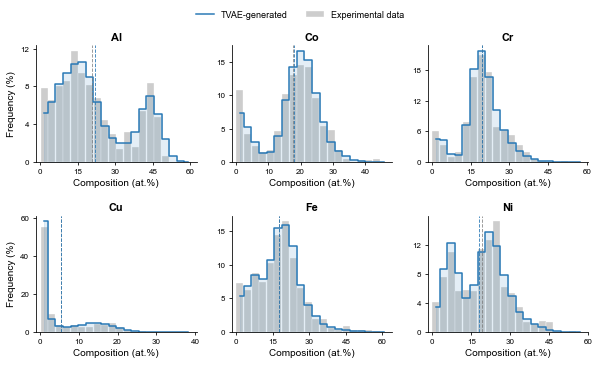


Mean Composition Comparison
Al | Experimental =  20.84 | TVAE =  22.00 at.%
Co | Experimental =  17.59 | TVAE =  17.92 at.%
Cr | Experimental =  19.46 | TVAE =  19.23 at.%
Cu | Experimental =   5.46 | TVAE =   5.26 at.%
Fe | Experimental =  17.53 | TVAE =  17.42 at.%
Ni | Experimental =  19.12 | TVAE =  18.17 at.%

Generated File:
TVAE_Composition_Distribution.png


In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ============================================================
# 1. Settings
# ============================================================

N_BINS = 20

FEATURES = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input files
DATA_FILE = BASE_DIR / "Data.xlsx"
GENERATED_FILE = BASE_DIR / "TVAE_Generated_Compositions.csv"

# Output figure
FIGURE_FILE = BASE_DIR / "TVAE_Composition_Distribution.png"


# ============================================================
# 2. Load data
# ============================================================

experimental_data = pd.read_excel(
    DATA_FILE
)

generated_data = pd.read_csv(
    GENERATED_FILE
)


# Check required composition columns
for file_name, dataset in [
    ("Experimental data", experimental_data),
    ("TVAE-generated data", generated_data),
]:

    missing_features = [
        feature
        for feature in FEATURES
        if feature not in dataset.columns
    ]

    if missing_features:

        raise ValueError(
            f"{file_name} is missing columns: "
            f"{missing_features}"
        )


experimental_composition = (
    experimental_data[FEATURES]
    .copy()
)

generated_composition = (
    generated_data[FEATURES]
    .copy()
)


print("=" * 65)
print("TVAE Composition Distribution")
print("=" * 65)

print(
    f"Experimental samples : "
    f"{len(experimental_composition):,}"
)

print(
    f"Generated samples    : "
    f"{len(generated_composition):,}"
)


# ============================================================
# 3. Plot style
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "axes.linewidth": 0.8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 9,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})


# ============================================================
# 4. Create figure
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(8.4, 5.1),
)

axes = axes.flatten()


# ============================================================
# 5. Plot elemental distributions
# ============================================================

for index, feature in enumerate(FEATURES):

    ax = axes[index]


    # --------------------------------------------------------
    # Extract data
    # --------------------------------------------------------

    experimental_values = (
        experimental_composition[feature]
        .dropna()
        .astype(float)
        .to_numpy()
    )

    generated_values = (
        generated_composition[feature]
        .dropna()
        .astype(float)
        .to_numpy()
    )


    # --------------------------------------------------------
    # Common histogram range
    # --------------------------------------------------------

    combined_values = np.concatenate(
        [
            experimental_values,
            generated_values,
        ]
    )


    value_min = combined_values.min()
    value_max = combined_values.max()

    value_range = (
        value_max
        - value_min
    )


    padding = (
        value_range * 0.03
        if value_range > 0
        else 1
    )


    plot_min = (
        value_min
        - padding
    )

    plot_max = (
        value_max
        + padding
    )


    bin_edges = np.linspace(
        value_min,
        value_max,
        N_BINS + 1,
    )


    # --------------------------------------------------------
    # Histogram counts
    # --------------------------------------------------------

    experimental_count, _ = np.histogram(
        experimental_values,
        bins=bin_edges,
    )

    generated_count, _ = np.histogram(
        generated_values,
        bins=bin_edges,
    )


    # --------------------------------------------------------
    # Convert to frequency (%)
    # --------------------------------------------------------

    experimental_frequency = (
        experimental_count
        / experimental_count.sum()
        * 100
    )

    generated_frequency = (
        generated_count
        / generated_count.sum()
        * 100
    )


    # --------------------------------------------------------
    # Histogram geometry
    # --------------------------------------------------------

    bin_centers = (
        bin_edges[:-1]
        + bin_edges[1:]
    ) / 2


    bin_width = (
        bin_edges[1]
        - bin_edges[0]
    )


    # --------------------------------------------------------
    # Experimental distribution
    # --------------------------------------------------------

    ax.bar(
        bin_centers,
        experimental_frequency,
        width=bin_width * 0.92,
        color="#BDBDBD",
        alpha=0.75,
        edgecolor="white",
        linewidth=0.45,
        label="Experimental data",
        zorder=1,
    )


    # --------------------------------------------------------
    # TVAE-generated distribution
    # --------------------------------------------------------

    ax.fill_between(
        bin_centers,
        generated_frequency,
        step="mid",
        color="#4C92C3",
        alpha=0.15,
        zorder=2,
    )


    ax.step(
        bin_centers,
        generated_frequency,
        where="mid",
        color="#2878B5",
        linewidth=1.5,
        label="TVAE-generated",
        zorder=3,
    )


    # --------------------------------------------------------
    # Mean composition
    # --------------------------------------------------------

    experimental_mean = np.mean(
        experimental_values
    )

    generated_mean = np.mean(
        generated_values
    )


    ax.axvline(
        experimental_mean,
        color="#777777",
        linestyle="--",
        linewidth=0.9,
        alpha=0.8,
        zorder=4,
    )


    ax.axvline(
        generated_mean,
        color="#2878B5",
        linestyle="--",
        linewidth=0.9,
        alpha=0.9,
        zorder=4,
    )


    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_title(
        feature,
        fontweight="bold",
        pad=5,
    )


    ax.set_xlabel(
        "Composition (at.%)"
    )


    if index in [0, 3]:

        ax.set_ylabel(
            "Frequency (%)"
        )


    # --------------------------------------------------------
    # Axis formatting
    # --------------------------------------------------------

    ax.set_xlim(
        plot_min,
        plot_max,
    )


    ax.set_ylim(
        bottom=0
    )


    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


    ax.tick_params(
        axis="both",
        direction="out",
        width=0.8,
        length=3,
    )


    ax.xaxis.set_major_locator(
        MaxNLocator(
            nbins=5
        )
    )


    ax.yaxis.set_major_locator(
        MaxNLocator(
            nbins=4
        )
    )


    ax.grid(False)


# ============================================================
# 6. Shared legend
# ============================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)


unique_legend = {}

for handle, label in zip(
    handles,
    labels,
):

    if label not in unique_legend:

        unique_legend[label] = handle


fig.legend(
    unique_legend.values(),
    unique_legend.keys(),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=2,
    frameon=False,
    columnspacing=2.0,
    handlelength=2.0,
)


# ============================================================
# 7. Layout
# ============================================================

plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.94,
    ],
    w_pad=1.8,
    h_pad=1.7,
)


# ============================================================
# 8. Save figure
# ============================================================

plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 9. Summary statistics
# ============================================================

print("\n" + "=" * 65)
print("Mean Composition Comparison")
print("=" * 65)


for feature in FEATURES:

    experimental_values = (
        experimental_composition[feature]
        .dropna()
        .to_numpy()
    )

    generated_values = (
        generated_composition[feature]
        .dropna()
        .to_numpy()
    )


    print(
        f"{feature:2s} | "
        f"Experimental = "
        f"{np.mean(experimental_values):6.2f} | "
        f"TVAE = "
        f"{np.mean(generated_values):6.2f} at.%"
    )


print("\nGenerated File:")

print(
    FIGURE_FILE.name
)

UMAP Comparison

C:\Users\Libin Zhang\anaconda3\envs\pytorch\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TVAE UMAP Comparison
Experimental samples : 500
Generated samples    : 50,000
Generated samples used for fitting : 5,000

Fitting UMAP
UMAP transformation completed.


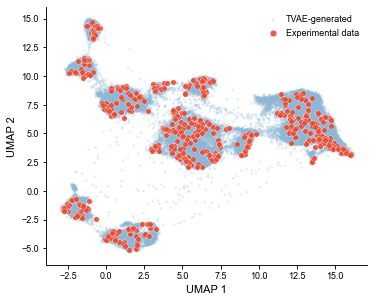


Completed
Figure saved as : TVAE_UMAP.png


In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap


# ============================================================
# 1. Settings
# ============================================================

RANDOM_STATE = 42

# Number of generated samples used to fit UMAP
N_GENERATED_FOR_FIT = 5_000

# Plot all generated compositions after UMAP fitting
PLOT_ALL_GENERATED = True


FEATURES = [
    "Al",
    "Co",
    "Cr",
    "Cu",
    "Fe",
    "Ni",
]


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input files
DATA_FILE = BASE_DIR / "Data.xlsx"
GENERATED_FILE = BASE_DIR / "TVAE_Generated_Compositions.csv"

# Output figure
FIGURE_FILE = BASE_DIR / "TVAE_UMAP.png"


# ============================================================
# 2. Load data
# ============================================================

experimental_data = pd.read_excel(
    DATA_FILE
)

generated_data = pd.read_csv(
    GENERATED_FILE
)


# Check required features
for file_name, dataset in [
    ("Experimental data", experimental_data),
    ("TVAE-generated data", generated_data),
]:

    missing_features = [
        feature
        for feature in FEATURES
        if feature not in dataset.columns
    ]

    if missing_features:

        raise ValueError(
            f"{file_name} is missing columns: "
            f"{missing_features}"
        )


experimental_X = (
    experimental_data[FEATURES]
    .dropna()
    .astype(float)
    .reset_index(drop=True)
)


generated_X = (
    generated_data[FEATURES]
    .dropna()
    .astype(float)
    .reset_index(drop=True)
)


print("=" * 65)
print("TVAE UMAP Comparison")
print("=" * 65)

print(
    f"Experimental samples : "
    f"{len(experimental_X):,}"
)

print(
    f"Generated samples    : "
    f"{len(generated_X):,}"
)


# ============================================================
# 3. Sample generated data for UMAP fitting
# ============================================================
#
# Only a subset of generated samples is used to fit UMAP
# so that the much larger synthetic dataset does not dominate
# the embedding structure.
#
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


if len(generated_X) > N_GENERATED_FOR_FIT:

    fit_indices = rng.choice(
        len(generated_X),
        size=N_GENERATED_FOR_FIT,
        replace=False,
    )

    generated_fit = (
        generated_X
        .iloc[fit_indices]
        .reset_index(drop=True)
    )

else:

    generated_fit = (
        generated_X
        .copy()
        .reset_index(drop=True)
    )


print(
    f"Generated samples used for fitting : "
    f"{len(generated_fit):,}"
)


# ============================================================
# 4. Prepare data for UMAP
# ============================================================

fit_data = pd.concat(
    [
        experimental_X,
        generated_fit,
    ],
    ignore_index=True,
)


# Standardization
scaler = StandardScaler()

fit_scaled = scaler.fit_transform(
    fit_data
)

experimental_scaled = scaler.transform(
    experimental_X
)

generated_scaled = scaler.transform(
    generated_X
)


# ============================================================
# 5. Fit UMAP
# ============================================================

umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.15,
    n_components=2,
    metric="euclidean",
    random_state=RANDOM_STATE,
)


print("\n" + "=" * 65)
print("Fitting UMAP")
print("=" * 65)


umap_model.fit(
    fit_scaled
)


# ============================================================
# 6. Transform data
# ============================================================

experimental_umap = umap_model.transform(
    experimental_scaled
)


if PLOT_ALL_GENERATED:

    generated_umap = umap_model.transform(
        generated_scaled
    )

else:

    generated_fit_scaled = scaler.transform(
        generated_fit
    )

    generated_umap = umap_model.transform(
        generated_fit_scaled
    )


print(
    "UMAP transformation completed."
)


# ============================================================
# 7. Plot style
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "axes.labelsize": 11,
    "axes.linewidth": 0.9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
})


# ============================================================
# 8. Create figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(5.2, 4.2)
)


# ------------------------------------------------------------
# TVAE-generated compositions
# ------------------------------------------------------------

ax.scatter(
    generated_umap[:, 0],
    generated_umap[:, 1],
    s=7,
    color="#8DB7D6",
    alpha=0.22,
    edgecolors="none",
    label="TVAE-generated",
    zorder=1,
)


# ------------------------------------------------------------
# Experimental compositions
# ------------------------------------------------------------

ax.scatter(
    experimental_umap[:, 0],
    experimental_umap[:, 1],
    s=30,
    color="#E64B35",
    alpha=0.90,
    edgecolors="white",
    linewidth=0.35,
    label="Experimental data",
    zorder=3,
)


# ============================================================
# 9. Axis formatting
# ============================================================

ax.set_xlabel(
    "UMAP 1"
)

ax.set_ylabel(
    "UMAP 2"
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


ax.tick_params(
    axis="both",
    direction="out",
    width=0.9,
    length=3.5,
)


ax.grid(False)


# ============================================================
# 10. Legend
# ============================================================

ax.legend(
    loc="best",
    frameon=False,
    markerscale=1.2,
    handletextpad=0.4,
)


# ============================================================
# 11. Save figure
# ============================================================

plt.tight_layout(
    pad=0.8
)


plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()


# ============================================================
# 12. Summary
# ============================================================

print("\n" + "=" * 65)
print("Completed")
print("=" * 65)

print(
    f"Figure saved as : "
    f"{FIGURE_FILE.name}"
)

Random Forest Prediction for TVAE-Generated Compositions

In [3]:
from pathlib import Path

import joblib
import pandas as pd


# ============================================================
# 1. Settings
# ============================================================

TOP_N = 1000


try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


# Input files
MODEL_FILE = BASE_DIR / "RF_Hardness_Model.joblib"
TVAE_FILE = BASE_DIR / "TVAE_Generated_Compositions.csv"

# Output files
PREDICTION_FILE = BASE_DIR / "TVAE_RF_Predictions.csv"
TOP_CANDIDATES_FILE = BASE_DIR / "TVAE_RF_Top1000_Candidates.xlsx"


# ============================================================
# 2. Load trained Random Forest model
# ============================================================

model_package = joblib.load(
    MODEL_FILE
)


model = model_package["model"]
feature_names = model_package["features"]
target_name = model_package["target"]


print("=" * 65)
print("RF Prediction for TVAE-Generated Compositions")
print("=" * 65)

print(
    f"Target   : "
    f"{target_name}"
)

print(
    f"Features : "
    f"{feature_names}"
)


# ============================================================
# 3. Load TVAE-generated compositions
# ============================================================

generated_data = pd.read_csv(
    TVAE_FILE
)


print(
    f"\nGenerated samples : "
    f"{len(generated_data):,}"
)


# ============================================================
# 4. Validate input features
# ============================================================

missing_features = [
    feature
    for feature in feature_names
    if feature not in generated_data.columns
]


if missing_features:

    raise ValueError(
        f"Missing RF input features: "
        f"{missing_features}"
    )


# ============================================================
# 5. Prepare RF input
# ============================================================
#
# The RF input uses exactly the same feature order
# as the original model training.
#
# Sample_ID is not used as an RF input feature.
#
# ============================================================

X_generated = generated_data[
    feature_names
].copy()


# ============================================================
# 6. Predict hardness
# ============================================================

print("\n" + "=" * 65)
print("Predicting Hardness")
print("=" * 65)


predicted_hv = model.predict(
    X_generated
)


# ============================================================
# 7. Combine compositions and predictions
# ============================================================

results = generated_data.copy()

results[
    "Predicted_Hv"
] = predicted_hv


# ============================================================
# 8. Rank candidates
# ============================================================

results = (
    results
    .sort_values(
        "Predicted_Hv",
        ascending=False,
    )
    .reset_index(drop=True)
)


results.insert(
    0,
    "Rank",
    range(
        1,
        len(results) + 1,
    ),
)


# ============================================================
# 9. Save all predictions
# ============================================================

results.to_csv(
    PREDICTION_FILE,
    index=False,
)


# ============================================================
# 10. Save Top-N candidates
# ============================================================

top_candidates = results.head(
    TOP_N
).copy()


top_candidates.to_excel(
    TOP_CANDIDATES_FILE,
    index=False,
)


# ============================================================
# 11. Summary
# ============================================================

print("\n" + "=" * 65)
print("TVAE Prediction Completed")
print("=" * 65)


print(
    f"Candidates predicted : "
    f"{len(results):,}"
)

print(
    f"Candidates retained  : "
    f"{len(top_candidates):,}"
)

print(
    f"Highest predicted Hv : "
    f"{results['Predicted_Hv'].max():.3f}"
)

print(
    f"Mean predicted Hv    : "
    f"{results['Predicted_Hv'].mean():.3f}"
)

print(
    f"Median predicted Hv  : "
    f"{results['Predicted_Hv'].median():.3f}"
)

print(
    f"Lowest predicted Hv  : "
    f"{results['Predicted_Hv'].min():.3f}"
)


print(
    f"\nCandidates > 500 Hv : "
    f"{(results['Predicted_Hv'] > 500).sum():,}"
)


# ============================================================
# 12. Display Top 20 candidates
# ============================================================

display_columns = [
    column
    for column in (
        ["Rank", "Sample_ID"]
        + feature_names
        + ["Predicted_Hv"]
    )
    if column in results.columns
]


print("\n" + "=" * 65)
print("Top 20 TVAE-Generated Candidates")
print("=" * 65)


print(
    results[
        display_columns
    ]
    .head(20)
    .to_string(
        index=False
    )
)


# ============================================================
# 13. Generated files
# ============================================================

print("\nGenerated Files:")

print(
    f"1. {PREDICTION_FILE.name}"
)

print(
    f"2. {TOP_CANDIDATES_FILE.name}"
)

RF Prediction for TVAE-Generated Compositions
Target   : Hv
Features : ['Al', 'Co', 'Cr', 'Cu', 'Fe', 'Ni']

Generated samples : 50,000

Predicting Hardness

TVAE Prediction Completed
Candidates predicted : 50,000
Candidates retained  : 1,000
Highest predicted Hv : 873.136
Mean predicted Hv    : 491.650
Median predicted Hv  : 462.480
Lowest predicted Hv  : 145.242

Candidates > 500 Hv : 21,435

Top 20 TVAE-Generated Candidates
 Rank  Sample_ID        Al        Co        Cr       Cu       Fe       Ni  Predicted_Hv
    1 TVAE_48479 44.464141 24.406432 20.148228 0.662599 6.314187 4.004414    873.135663
    2 TVAE_10191 44.755913 20.044721 20.399094 0.656346 7.259444 6.884482    872.468895
    3 TVAE_37522 44.226198 21.215756 20.006585 0.624760 8.230835 5.695867    871.825236
    4 TVAE_43113 44.054785 22.894949 20.383541 0.296758 6.683170 5.686797    871.524163
    5 TVAE_23992 44.125249 22.758864 20.347556 0.311378 6.754477 5.702476    871.156578
    6 TVAE_38599 43.887133 22.565158 20.7